<a href="https://colab.research.google.com/github/axelr004/AD_2026Q4_Grupo20/blob/main/graficosparte3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

librerias

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Cargar datos

In [ ]:
URL_MED = "https://raw.githubusercontent.com/axelr004/AD_2026Q4_Grupo20/main/AE3/datos/medellin.csv"

URL_MAD = "https://raw.githubusercontent.com/axelr004/AD_2026Q4_Grupo20/main/AE3/datos/madrid.csv"

medellin = pd.read_csv(URL_MED)
madrid = pd.read_csv(URL_MAD)

medellin["fecha"] = pd.to_datetime(medellin["fecha"])
madrid["fecha"] = pd.to_datetime(madrid["fecha"])

Unir los datos

In [ ]:
comparacion = pd.merge( medellin,
                         madrid,
                         on="fecha",
                         how="inner",
                         suffixes=("_med", "_mad") )

columnas = [ "temperatura_max_c_med", "precipitacion_mm_med", "temperatura_max_c_mad", "precipitacion_mm_mad"]

comparacion = comparacion.dropna(subset=columnas).copy()

comparacion["mes"] = comparacion["fecha"].dt.month

Calcular los promedios y acumulados mensuales

In [ ]:
mensual = comparacion.groupby("mes").agg({ "temperatura_max_c_med": "mean", "temperatura_max_c_mad": "mean",
    "precipitacion_mm_med": "sum", "precipitacion_mm_mad": "sum" })

display(mensual)

,temperatura_max_c_med,temperatura_max_c_mad,precipitacion_mm_med,precipitacion_mm_mad
mes,,,,
1,25.758065,10.354839,219.3,21.4
2,26.428571,12.885714,146.3,5.8
3,25.425806,18.741935,432.2,9.0
4,26.286667,24.350000,414.3,6.9
5,27.570968,23.525806,306.6,43.1
6,28.413333,28.846667,166.2,41.9
7,29.206452,34.267742,138.3,3.2
8,29.719355,34.687097,154.4,0.0
9,29.690000,25.386667,143.3,128.0


grafica de temperaturas

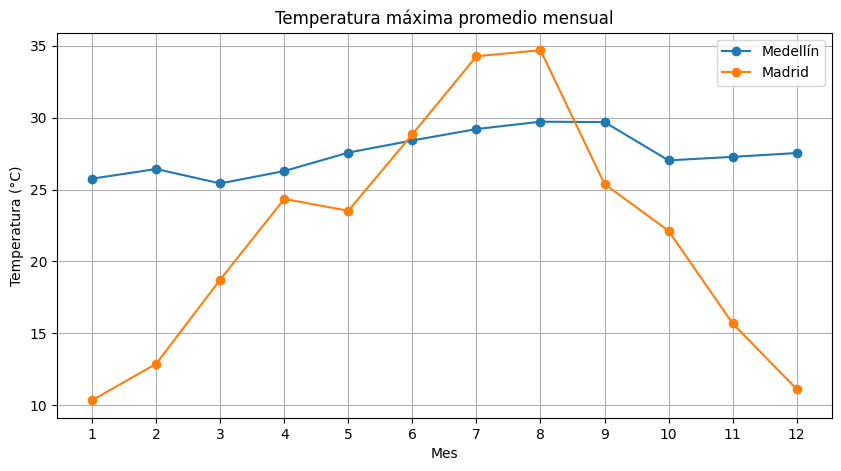

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(mensual.index, mensual["temperatura_max_c_med"], marker="o", label="Medellín")

plt.plot(mensual.index, mensual["temperatura_max_c_mad"], marker="o", label="Madrid")

plt.title("Temperatura máxima promedio mensual")
plt.xlabel("Mes")
plt.ylabel("Temperatura (°C)")
plt.xticks(range(1,13))
plt.legend()
plt.grid()
plt.show()

grafica de precipitaciones

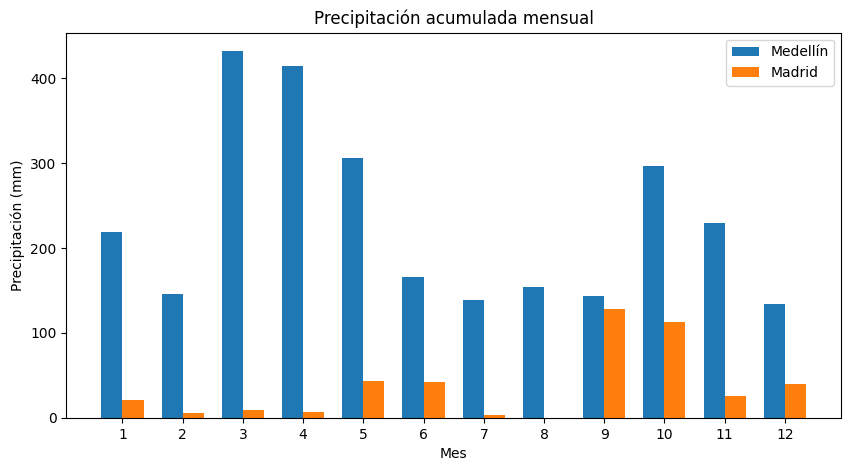

In [ ]:
x = np.arange(len(mensual))
ancho = 0.35

plt.figure(figsize=(10,5))

plt.bar(x - ancho/2, mensual["precipitacion_mm_med"], ancho, label="Medellín")

plt.bar(x + ancho/2, mensual["precipitacion_mm_mad"], ancho, label="Madrid")

plt.title("Precipitación acumulada mensual")
plt.xlabel("Mes")
plt.ylabel("Precipitación (mm)")
plt.xticks(x, mensual.index)
plt.legend()
plt.show()

histogramas

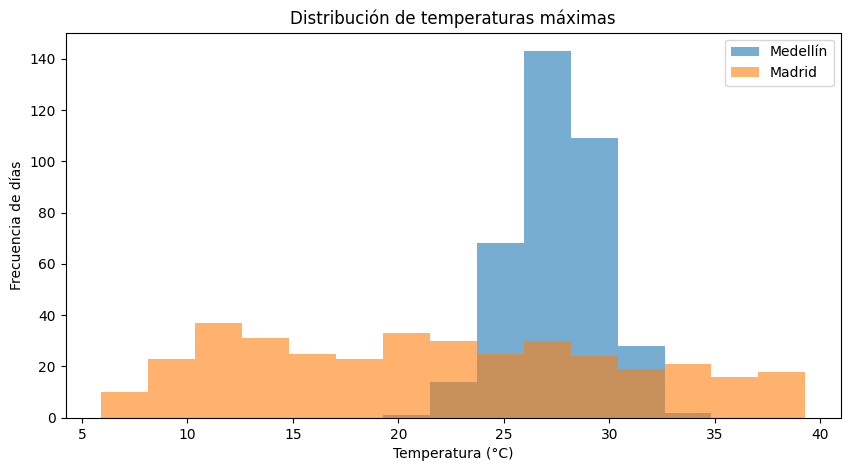

In [ ]:
plt.figure(figsize=(10,5))

bins = np.histogram_bin_edges(
    np.concatenate([
        comparacion["temperatura_max_c_med"].to_numpy(),
        comparacion["temperatura_max_c_mad"].to_numpy() ]), bins=15 )

plt.hist(comparacion["temperatura_max_c_med"], bins=bins, alpha=0.6, label="Medellín")

plt.hist(comparacion["temperatura_max_c_mad"], bins=bins, alpha=0.6, label="Madrid")

plt.title("Distribución de temperaturas máximas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Frecuencia de días")
plt.legend()
plt.show()